# FitFlex: Pose Detection, step by step

This notebook explains how the FitFlex pose detector (`pose_detector.py`) works, one idea at a time:

1. Imports and versions
2. Finding the 33 body landmarks on a sample image
3. The angle function, with a worked example
4. Squat logic: knee angle → rep counting and form checks
5. Bicep curl logic
6. Running live on the webcam
7. Why MediaPipe? (algorithm comparison from the project report)

Run the cells from top to bottom with **Shift + Enter**. Use the `.venv` kernel (see README.md).

## 1. Imports

In [1]:
import cv2
import mediapipe as mp
import numpy as np
import matplotlib.pyplot as plt

from pose_utils import calculate_angle
from pose_detector import SquatTracker, BicepCurlTracker, CONFIG, LANDMARKS

plt.rcParams["figure.dpi"] = 80   # keeps the saved notebook small

print("OpenCV   ", cv2.__version__)
print("MediaPipe", mp.__version__)
print("NumPy    ", np.__version__)

OpenCV    4.11.0
MediaPipe 0.10.21
NumPy     1.26.4


## 2. Landmarks on a sample image

MediaPipe Pose finds **33 landmarks** (nose, eyes, shoulders, elbows, wrists, hips, knees, ankles, feet...).
Each landmark has:

* `x`, `y`: position as a **fraction** of the image width/height (0.0 – 1.0)
* `z`: rough depth (smaller = closer to the camera)
* `visibility`: how sure the model is that the point is visible (0 – 1)

Important: OpenCV loads images as **BGR**, but MediaPipe expects **RGB**, so we convert first.

*Sample photo: "Personal training kettle bell squat" by PTPioneer, CC BY 2.0, via Wikimedia Commons.*

Landmarks found: 33
LEFT_SHOULDER  x=0.421  y=0.582  visibility=1.00
LEFT_HIP       x=0.401  y=0.773  visibility=1.00
LEFT_KNEE      x=0.475  y=0.796  visibility=0.98
LEFT_ANKLE     x=0.462  y=0.900  visibility=0.97


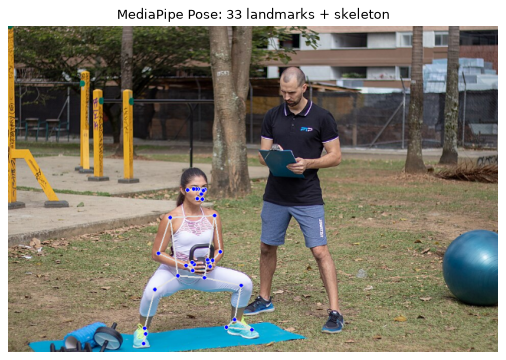

In [2]:
image_bgr = cv2.imread("assets/sample_squat.jpg")
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
height, width = image_rgb.shape[:2]

mp_pose = mp.solutions.pose
mp_drawing = mp.solutions.drawing_utils

# static_image_mode=True: treat the input as an independent photo, not a video stream.
with mp_pose.Pose(static_image_mode=True, model_complexity=1) as pose:
    results = pose.process(image_rgb)

landmarks = results.pose_landmarks.landmark
print("Landmarks found:", len(landmarks))
for name in ["LEFT_SHOULDER", "LEFT_HIP", "LEFT_KNEE", "LEFT_ANKLE"]:
    lm = landmarks[mp_pose.PoseLandmark[name]]
    print(f"{name:14} x={lm.x:.3f}  y={lm.y:.3f}  visibility={lm.visibility:.2f}")

annotated = image_rgb.copy()
mp_drawing.draw_landmarks(annotated, results.pose_landmarks, mp_pose.POSE_CONNECTIONS)
annotated = cv2.resize(annotated, (640, int(640 * height / width)))  # smaller copy just for display
plt.figure(figsize=(8, 5.3))
plt.imshow(annotated)
plt.axis("off")
plt.title("MediaPipe Pose: 33 landmarks + skeleton")
plt.show()

## 3. The angle function

For three points **A – B – C** we want the angle **at B**, e.g. hip – knee – ankle gives the knee angle.

`atan2(dy, dx)` returns the direction of a line (in radians). The angle at B is the difference between
the direction **B → C** and the direction **B → A**:

```
angle = | atan2(Cy - By, Cx - Bx) - atan2(Ay - By, Ax - Bx) |   (converted to degrees)
if angle > 180: angle = 360 - angle        # a joint is never bent more than 180
```

**Worked example:** A = (0, 1), B = (0, 0), C = (1, 0)

* direction B → C = atan2(0, 1) = 0°
* direction B → A = atan2(1, 0) = 90°
* |0° − 90°| = **90°**, a right angle ✔

Why `atan2` and not `atan`? `atan(dy/dx)` cannot tell opposite directions apart and fails when `dx = 0`;
`atan2` uses the signs of both values, so it works in all four quadrants.

In [3]:
print("Right angle :", calculate_angle((0, 1), (0, 0), (1, 0)))
print("Straight leg:", calculate_angle((0, 0), (0, 1), (0, 2)))
print("45 degrees  :", round(calculate_angle((1, 0), (0, 0), (1, 1)), 1))

# Now on the real photo. Use PIXELS, not fractions: the image is not square, so fractions would distort angles.
def pixel(name):
    lm = landmarks[mp_pose.PoseLandmark[name]]
    return (lm.x * width, lm.y * height)

for side in ["LEFT", "RIGHT"]:
    knee = calculate_angle(pixel(f"{side}_HIP"), pixel(f"{side}_KNEE"), pixel(f"{side}_ANKLE"))
    torso = calculate_angle(pixel(f"{side}_SHOULDER"), pixel(f"{side}_HIP"), pixel(f"{side}_KNEE"))
    print(f"{side:5} knee = {knee:5.1f} deg   torso = {torso:5.1f} deg")

Right angle : 90.0
Straight leg: 180.0
45 degrees  : 45.0
LEFT  knee =  90.0 deg   torso =  92.1 deg
RIGHT knee = 135.4 deg   torso = 113.0 deg


The two legs give different numbers: the left knee is ~90° (a proper squat), but the right leg points
towards the camera, so in this flat 2D picture it *looks* straighter than it is. That is why the detector
uses the side the camera sees best, and why you should **stand sideways** to the camera for squats and curls.

## 4. Squat logic

The detector keeps a tiny **state machine** with two stages:

| Stage | Condition | Meaning |
|---|---|---|
| `up` | knee angle > 160° | standing |
| `down` | knee angle < 90° | deep enough |

A **rep** is counted on the change `down → up`. If you come back up without going below 90°,
the rep is not counted and the feedback says **"Go lower"**.

Form check: the torso angle (shoulder – hip – knee) must stay above 50° while squatting,
otherwise **"Keep chest up"** and the frame counts as *wrong posture*.
The correct-form % in the summary is `correct frames / tracked frames × 100`.

Below we feed the tracker a made-up sequence of knee angles (two good reps and one shallow rep)
and plot it with the thresholds.

Reps counted: 2
Feedback messages: [(37, 'Good rep!'), (103, 'Go lower')]
Correct form %: 84.0


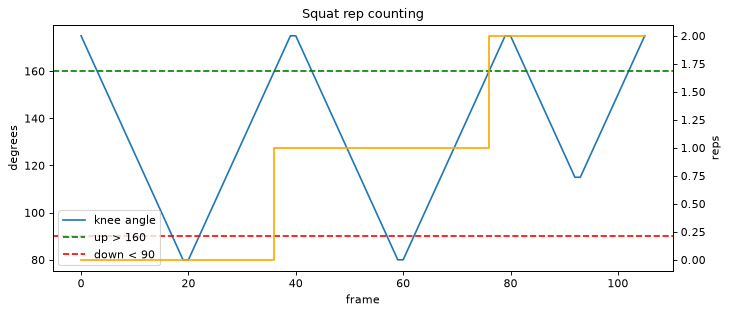

In [4]:
import math

def squat_points(knee_angle, torso_angle=165):
    """Builds hip/knee/ankle/shoulder points with exactly these angles (for the demo)."""
    def at_angle(vertex, other, angle, length=100):
        dx, dy = other[0] - vertex[0], other[1] - vertex[1]
        n = math.hypot(dx, dy); r = math.radians(angle)
        ux, uy = dx / n, dy / n
        return (vertex[0] + length * (ux * math.cos(r) - uy * math.sin(r)),
                vertex[1] + length * (ux * math.sin(r) + uy * math.cos(r)))
    ankle, knee = (300, 450), (300, 350)
    hip = at_angle(knee, ankle, knee_angle)
    return {"ANKLE": ankle, "KNEE": knee, "HIP": hip, "SHOULDER": at_angle(hip, knee, torso_angle)}

# Two full squats, then a shallow one (only down to 115 deg)
down_up = list(range(175, 79, -5)) + list(range(80, 176, 5))
shallow = list(range(175, 114, -5)) + list(range(115, 176, 5))
sequence = down_up + down_up + shallow

tracker = SquatTracker(dict(CONFIG, smoothing_window=1))
reps_over_time, messages = [], []
for i, angle in enumerate(sequence):
    t = i / 30
    tracker.update(squat_points(angle), t)
    reps_over_time.append(tracker.reps)
    msg = tracker.current_feedback(t)
    if msg and (not messages or messages[-1][1] != msg):
        messages.append((i, msg))

print("Reps counted:", tracker.reps)
print("Feedback messages:", messages)
print("Correct form %:", tracker.correct_form_percent)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(sequence, label="knee angle")
ax.axhline(CONFIG["squat_up_angle"], color="green", linestyle="--", label=f"up > {CONFIG['squat_up_angle']}")
ax.axhline(CONFIG["squat_down_angle"], color="red", linestyle="--", label=f"down < {CONFIG['squat_down_angle']}")
ax2 = ax.twinx(); ax2.step(range(len(reps_over_time)), reps_over_time, color="orange", label="reps"); ax2.set_ylabel("reps")
ax.set_xlabel("frame"); ax.set_ylabel("degrees"); ax.legend(loc="lower left"); ax.set_title("Squat rep counting")
plt.show()

## 5. Bicep curl logic

Same idea with the **elbow angle** (shoulder – elbow – wrist):

`straight (> 160°) → curled (< 40°) → straight again` = 1 rep.

Form checks:
* **"Keep elbow close"**: the upper arm (hip – shoulder – elbow angle) swings forward by more than 35°.
* **"Extend arm fully"**: the arm opens only part-way (more than 90° but not 160°) and curls again.

In [5]:
def curl_points(elbow_angle, upper_arm_angle=10):
    def at_angle(vertex, other, angle, length=100):
        dx, dy = other[0] - vertex[0], other[1] - vertex[1]
        n = math.hypot(dx, dy); r = math.radians(angle)
        ux, uy = dx / n, dy / n
        return (vertex[0] + length * (ux * math.cos(r) - uy * math.sin(r)),
                vertex[1] + length * (ux * math.sin(r) + uy * math.cos(r)))
    hip, shoulder = (300, 400), (300, 250)
    elbow = at_angle(shoulder, hip, upper_arm_angle)
    return {"HIP": hip, "SHOULDER": shoulder, "ELBOW": elbow, "WRIST": at_angle(elbow, shoulder, elbow_angle)}

full_curl = [170, 140, 100, 60, 30, 60, 100, 140, 170]
lazy_curl = [170, 100, 30, 80, 120, 80, 30, 100, 170]   # opens only to 120 in the middle

curl = BicepCurlTracker(dict(CONFIG, smoothing_window=1))
reps_before = 0
for i, angle in enumerate(full_curl * 3 + lazy_curl):
    curl.update(curl_points(angle), i / 30)
    if curl.reps != reps_before:
        print(f"frame {i:2}: rep {curl.reps} counted")
        reps_before = curl.reps
    if curl.issue == "Extend arm fully":
        print(f"frame {i:2}: Extend arm fully  (curled again without straightening the arm)")
print("Bicep reps:", curl.reps)
print("The lazy set opened only to 120 deg before curling again, so that middle curl was not counted;")
print("the 4th rep is counted only when the arm finally straightens past 160 deg.")

swinging = BicepCurlTracker(dict(CONFIG, smoothing_window=1))
swinging.update(curl_points(90, upper_arm_angle=60), 0)
print("Elbow swinging forward ->", swinging.issue)

frame  8: rep 1 counted
frame 17: rep 2 counted
frame 26: rep 3 counted
frame 33: Extend arm fully  (curled again without straightening the arm)
frame 35: rep 4 counted
Bicep reps: 4
The lazy set opened only to 120 deg before curling again, so that middle curl was not counted;
the 4th rep is counted only when the arm finally straightens past 160 deg.
Elbow swinging forward -> Keep elbow close


## 6. Live on the webcam

The full program adds drawing, an on-screen panel (exercise, reps, angles in **deg**, correct/wrong posture,
FPS) and keyboard controls: `s` squat, `b` bicep curl, `p` plank, `r` reset, `q` quit.

Set `RUN_WEBCAM = True` and run the cell. A window opens; press **q** in that window to stop.
(It is off by default so the notebook can run from top to bottom without a camera.)

In [6]:
RUN_WEBCAM = False

if RUN_WEBCAM:
    from pose_detector import main
    main(["--exercise", "squat"])          # add "--upload", "--email", ..., "--password", ... to save to FitFlex
else:
    print("Webcam demo skipped. Set RUN_WEBCAM = True to try it.")

Webcam demo skipped. Set RUN_WEBCAM = True to try it.


## 7. Why MediaPipe? Algorithm comparison

*Values from the FitFlex project report.*

| Algorithm | Accuracy (from project report) | Notes |
|---|---|---|
| **MediaPipe Pose** | **90%** | Real-time on a normal laptop CPU, 33 landmarks, easy Python API |
| OpenPose | 85% | Multi-person, but heavy and usually needs a GPU |
| HRNet | 78% | High-resolution network, research-oriented, slow without a GPU |
| AlphaPose | 76% | Multi-person, complex setup |

MediaPipe was chosen because it runs in real time on a CPU and installs with one `pip install`.

## Summary

* MediaPipe turns each frame into 33 landmarks.
* `calculate_angle` turns three landmarks into a joint angle using `atan2`.
* Simple thresholds + a two-stage state machine count reps and catch bad form.
* `pose_detector.py` puts it together live, and `--upload` saves the session to the FitFlex progress page
  (`POST /api/progress/pose`).